# **DSA 4060A – Market Basket Analysis Using Association Rule Mining**

**Student:** Kyeremateng Martin

**Student Number:** 669217

**Module:** DSA 4060A – Recommender Systems

**Date:** 12 October 2026

## Objective
Apply the Apriori algorithm to the Groceries dataset to:
1. Identify **frequent itemsets** at a chosen minimum support.
2. Generate **association rules** at a chosen minimum confidence.
3. Interpret the results and draw business conclusions.

# Step 1
**Imports** **&** **Setup**


Imports all libraries needed for the pipeline.

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings('ignore')

# Step 2
**Load Data**

Loads the CSV. Confirms number of rows and columns.



In [44]:
groceries = pd.read_csv('Groceries_dataset.csv')
print("Shape of raw data:", groceries.shape)
print("\nFirst 5 rows:")
groceries.head()

Shape of raw data: (38765, 3)

First 5 rows:


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


The dataset `Groceries_dataset.csv` is in **long (transactional) format** — one row per item purchased. Its columns are:
- `Member_number` – customer ID
- `Date` – date of purchase
- `itemDescription` – product purchased

Because each basket is spread across multiple rows, we will have to group rows into baskets before applying Apriori.

# Step 3
**Exploratory Data Analysis**

> We inspect the dataset's size, the number of unique customers and items, the date range, and the most frequently purchased products. This gives context before mining.

Reports key stats and plots the 15 most-purchased items

Total rows           : 38765
Unique customers     : 3898
Unique items         : 167
Date range           : 01-01-2014 to 31-10-2015


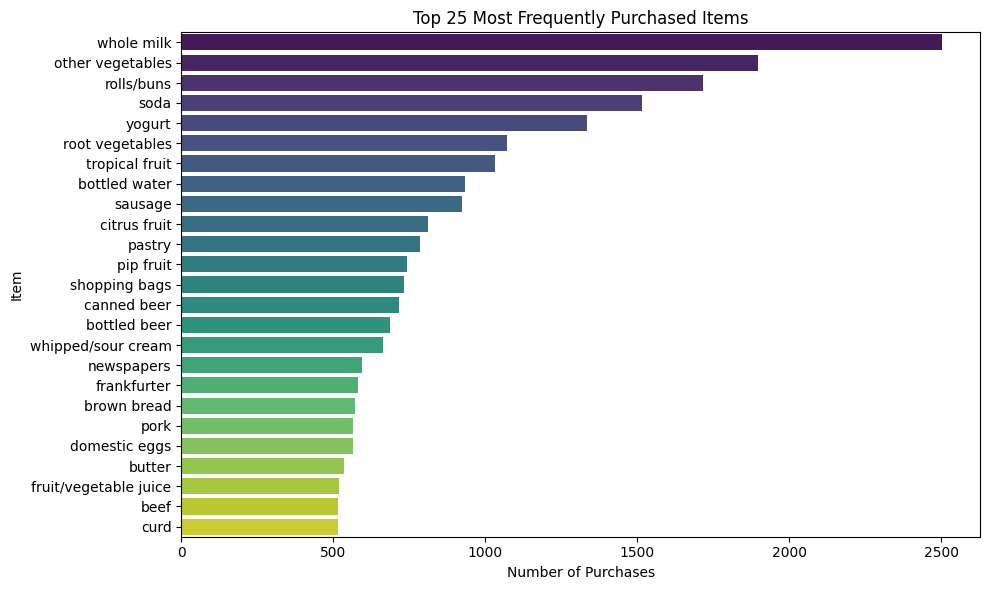

In [45]:

df_raw = groceries.copy()
print(f"Total rows           : {len(df_raw)}")
print(f"Unique customers     : {df_raw['Member_number'].nunique()}")
print(f"Unique items         : {df_raw['itemDescription'].nunique()}")
print(f"Date range           : {df_raw['Date'].min()} to {df_raw['Date'].max()}")

top_items = df_raw['itemDescription'].value_counts().head(25)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_items.values, y=top_items.index, palette='viridis')
plt.title('Top 25 Most Frequently Purchased Items')
plt.xlabel('Number of Purchases')
plt.ylabel('Item')
plt.tight_layout()
plt.show()

# Step 5

**Reconstructing Baskets**

In [46]:
baskets = groceries.groupby(['Member_number', 'Date'])['itemDescription'] \
                .apply(list).tolist()

print(f"Number of baskets       : {len(baskets)}")
print(f"Average items per basket: {np.mean([len(b) for b in baskets]):.2f}")
print(f"\nExample basket: {baskets[0]}")

Number of baskets       : 14963
Average items per basket: 2.59

Example basket: ['sausage', 'whole milk', 'semi-finished bread', 'yogurt']



Each shopping trip is identified by the combination of `Member_number` **and** `Date`. We group all items belonging to the same (customer, date) pair into a single list — this becomes one *basket*.

> **Assumption:** One customer = one basket per day. Multiple same-day trips would be merged into a single basket.

# Step 6

**One-Hot Encoding Baskets**

In [47]:
te = TransactionEncoder()
df = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
df = df.astype(bool)

print(f"Encoded dataframe shape : {df.shape}")
print(f"  → {df.shape[0]} baskets × {df.shape[1]} unique items")
print(f"Total True values       : {df.values.sum()}")

Encoded dataframe shape : (14963, 167)
  → 14963 baskets × 167 unique items
Total True values       : 38006


Apriori requires a **boolean matrix** where:
- Rows = baskets
- Columns = unique items
- Cell = `True` if item is in the basket, else `False`

> We use `TransactionEncoder` from `mlxtend` to perform this transformation.

# Step 7

**Mining Frequent Itemsets with Apriori**

In [48]:
frequent_itemsets = apriori(df, min_support=0.0005, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)

print("Frequent itemsets by length:")
print(frequent_itemsets['length'].value_counts().sort_index())

print("\nTop 10 itemsets by support:")
frequent_itemsets.sort_values('support', ascending=False).head(10)

Frequent itemsets by length:
length
1     158
2    1217
3      72
Name: count, dtype: int64

Top 10 itemsets by support:


,support,itemsets,length
155,0.157923,(whole milk),1
97,0.122101,(other vegetables),1
116,0.110005,(rolls/buns),1
130,0.097106,(soda),1
156,0.085879,(yogurt),1
117,0.069572,(root vegetables),1
147,0.067767,(tropical fruit),1
10,0.060683,(bottled water),1
122,0.060349,(sausage),1
28,0.053131,(citrus fruit),1


### Parameter Choice — `min_support = 0.0005`

**Support** = the fraction of all baskets that contain a given itemset.

**Why 0.0005?**
- 0.0005 × 14963 baskets ≈ between **7-8 baskets minimum** — enough to avoid one-off coincidences.
- Higher thresholds (0.01, 0.005) produced comparably negligible multi-item itemsets, meaning real patterns would be missed.
- Lower thresholds (0.0003) produced thousands of statistically fragile rules based on only ~5 baskets each.

> 0.0005 balances **statistical reliability** against **discovery richness**.

# Step 8

**Generating Association Rules**

### Parameter Choice — `min_confidence = 0.02`

**Confidence** = P(consequent | antecedent): *"If a customer buys X, how often do they also buy Y?"*

In [49]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.02)
rules = rules[rules['lift'] > 1.0]
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"Total rules generated (confidence ≥ 0.02, lift > 1.0): {len(rules)}")
print("\nTop 10 rules by lift:")
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

Total rules generated (confidence ≥ 0.02, lift > 1.0): 608

Top 10 rules by lift:


,antecedents,consequents,support,confidence,lift
0,(ham),(pickled vegetables),0.000535,0.031250,3.489506
1,(pickled vegetables),(ham),0.000535,0.059701,3.489506
2,(soft cheese),(hamburger meat),0.000601,0.060000,2.745505
3,(hamburger meat),(soft cheese),0.000601,0.027523,2.745505
4,"(sausage, pork)",(whole milk),0.000601,0.391304,2.477819
5,(sweet spreads),(pip fruit),0.000535,0.117647,2.398301
6,(sweet spreads),(tropical fruit),0.000735,0.161765,2.387066
7,"(rolls/buns, whipped/sour cream)",(yogurt),0.000601,0.204545,2.381800
8,(spices),(soda),0.000601,0.225000,2.317051
9,(mustard),(frankfurter),0.000535,0.086957,2.302886


### Refining Rules with `min_confidence = 0.10`

Filtering rules to require at least **10% confidence** focuses our analysis on stronger, more actionable business associations while maintaining high lift.



In [50]:
# Filter rules with minimum confidence of 10% and lift > 1.0
refined_rules = rules[(rules['confidence'] >= 0.10) & (rules['lift'] > 1.0)]
refined_rules = refined_rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"Total rules remaining (confidence ≥ 0.10, lift > 1.0): {len(refined_rules)}")
print("\nTop 10 refined rules sorted by lift:")
display(refined_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

Total rules remaining (confidence ≥ 0.10, lift > 1.0): 140

Top 10 refined rules sorted by lift:


,antecedents,consequents,support,confidence,lift
0,"(sausage, pork)",(whole milk),0.000601,0.391304,2.477819
1,(sweet spreads),(pip fruit),0.000535,0.117647,2.398301
2,(sweet spreads),(tropical fruit),0.000735,0.161765,2.387066
3,"(rolls/buns, whipped/sour cream)",(yogurt),0.000601,0.204545,2.381800
4,(spices),(soda),0.000601,0.225000,2.317051
5,"(shopping bags, sausage)",(other vegetables),0.000535,0.275862,2.259291
6,"(yogurt, whole milk)",(sausage),0.001470,0.131737,2.182917
7,"(pastry, soda)",(sausage),0.000535,0.131148,2.173157
8,(brandy),(whole milk),0.000869,0.342105,2.166281
9,"(pork, whole milk)",(sausage),0.000601,0.120000,1.988439





### **Note**

`min_confidence = 0.02` gave 608 coincidences and noise which after setting it a bit high to `min_conf = 0.1` cut `468` weak associations, leaving us with `140` higly meaningful rules to analyze

# Step 9

 **Interpreting the Top rules**




In [51]:
top_conf = rules.sort_values('confidence', ascending=False).head(10)
print("Top 10 rules by CONFIDENCE (most reliable):")
top_conf[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

Top 10 rules by CONFIDENCE (most reliable):


,antecedents,consequents,support,confidence,lift
4,"(sausage, pork)",(whole milk),0.000601,0.391304,2.477819
14,(brandy),(whole milk),0.000869,0.342105,2.166281
29,(softener),(whole milk),0.000802,0.292683,1.853328
38,"(rolls/buns, white bread)",(whole milk),0.000601,0.281250,1.780933
46,(artif. sweetener),(whole milk),0.000535,0.275862,1.746815
10,"(shopping bags, sausage)",(other vegetables),0.000535,0.275862,2.259291
66,"(sausage, yogurt)",(whole milk),0.001470,0.255814,1.619866
88,(house keeping products),(whole milk),0.000735,0.244444,1.547872
119,"(pastry, soda)",(whole milk),0.000936,0.229508,1.453293
120,"(sausage, pastry)",(whole milk),0.000735,0.229167,1.451130


For a rule `antecedents → consequents`:
- **Support** – how often this combination appears across all baskets
- **Confidence** – P(consequent | antecedent)
- **Lift** – how many times *more likely* the consequent is given the antecedent

> Rules come in **mirrored pairs** (`X → Y` and `Y → X`). Lift is identical in both directions; confidence differs because it depends on each item's base rate.

We examine the rules ranked by **confidence** separately, these are the most reliable implications.

# Step 10
**Visualization 1 — Support vs Confidence**

Each dot = one rule. Size and color reflect lift. Rules in the upper-right are both frequent and reliable.

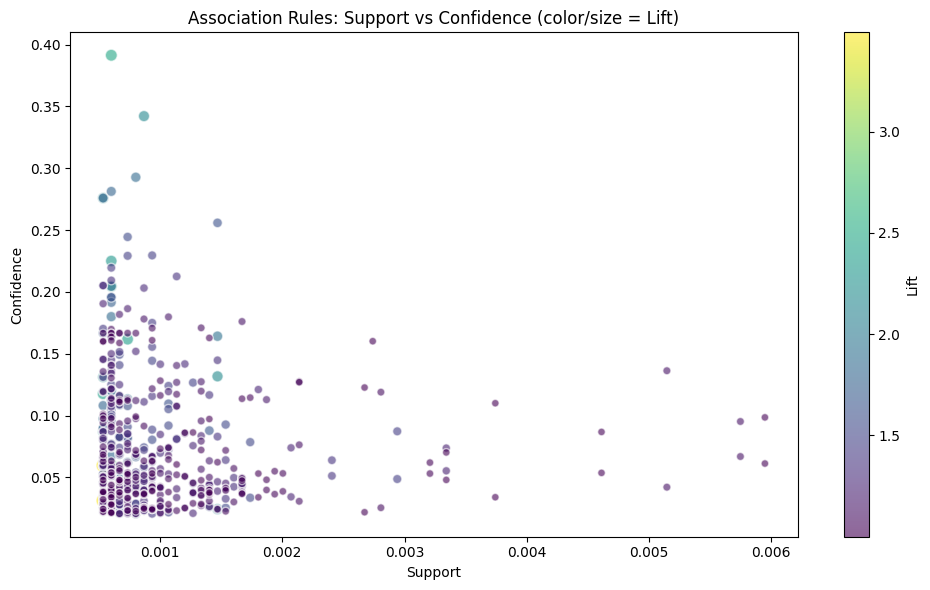

In [52]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(rules['support'], rules['confidence'],
                      c=rules['lift'], cmap='viridis',
                      s=rules['lift'] * 30, alpha=0.6, edgecolors='w')
plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Association Rules: Support vs Confidence (color/size = Lift)')
plt.tight_layout()
plt.show()

### Support vs. Confidence scatter plot:

The Axes:

> X-Axis (Support): How common the item combination is. Most dots are on the far left because buying specific item combinations is naturally rare.
Y-Axis (Confidence): How reliable the rule is (the probability that buying item A leads to buying item B). Higher dots are stronger rules.
Color & Size (Lift):

> Larger, brighter dots (yellow/green) represent rules with high Lift. This means the items are coupled because of a genuine relationship, not just random chance.
What to look for: The best rules are in the upper-right quadrant and colored yellow/green, meaning they are both common and highly reliable.

# Step 11

**Visualization 2: Top 10 Rules by Lift**

Bar chart of the strongest rules by lift.


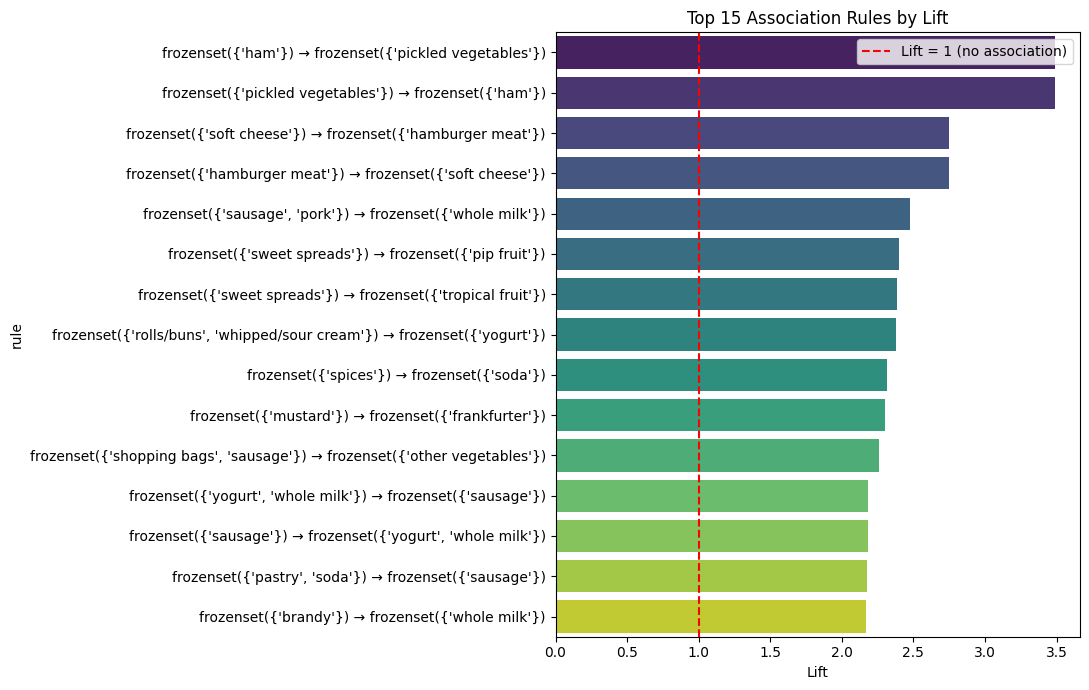

In [53]:
top15 = rules.head(15).copy()
top15['rule'] = top15['antecedents'].astype(str) + ' → ' + top15['consequents'].astype(str)

plt.figure(figsize=(11, 7))
sns.barplot(data=top15, y='rule', x='lift', palette='viridis')
plt.axvline(1.0, color='red', linestyle='--', label='Lift = 1 (no association)')
plt.title('Top 15 Association Rules by Lift')
plt.xlabel('Lift')
plt.legend()
plt.tight_layout()
plt.show()

Horizontal bar chart of the strongest rules. The red dashed line marks **lift = 1** (no association).

# Step 12

**Visualization 4: Frequest Item Pairs**

Bar chart of the most common co-purchases.

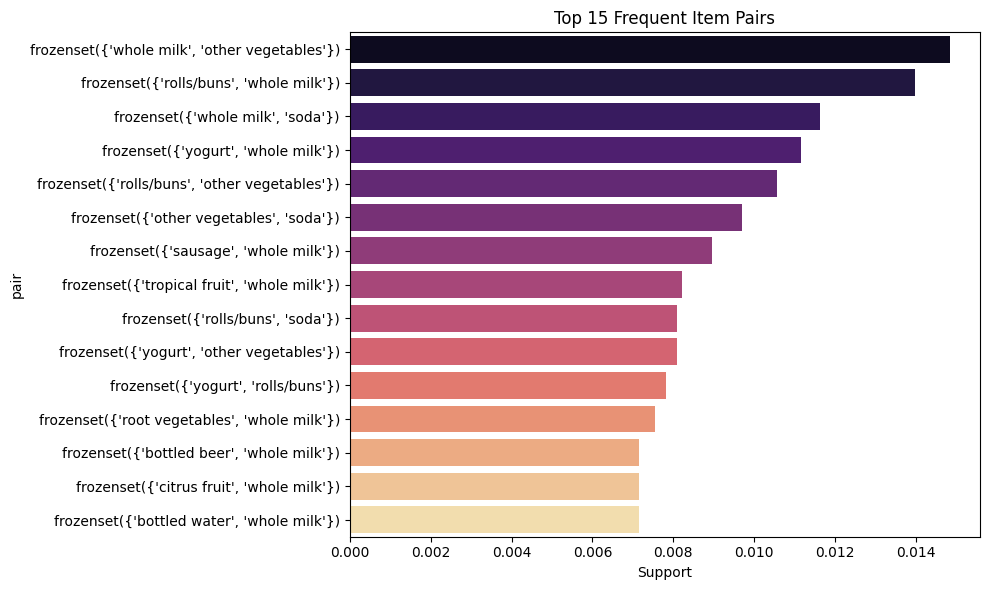

In [54]:
pairs = frequent_itemsets[frequent_itemsets['length'] == 2] \
        .sort_values('support', ascending=False).head(15).copy()
pairs['pair'] = pairs['itemsets'].astype(str)

plt.figure(figsize=(10, 6))
sns.barplot(data=pairs, y='pair', x='support', palette='magma')
plt.title('Top 15 Frequent Item Pairs')
plt.xlabel('Support')
plt.tight_layout()
plt.show()

Before filtering by rule metrics, the itemsets themselves reveal which pairs of products co-occur most often in absolute terms.

# Step 14

**Parameter Sensitivity**

Produces a small table showing itemset/rule counts at each support level

In [55]:
results = []
for s in [0.01, 0.005, 0.001, 0.0005, 0.0003]:
    fi = apriori(df, min_support=s, use_colnames=True)
    if len(fi) == 0:
        results.append({'min_support': s, 'itemsets': 0, 'multi_item': 0,
                        'rules': 0, 'max_lift': 0.0})
        continue
    fi['length'] = fi['itemsets'].apply(len)
    multi = fi[fi['length'] >= 2]
    r = association_rules(fi, metric="confidence", min_threshold=0.05)
    r = r[r['lift'] > 1.0]
    results.append({
        'min_support': s,
        'itemsets': len(fi),
        'multi_item': len(multi),
        'rules': len(r),
        'max_lift': round(r['lift'].max(), 3) if len(r) else 0.0
    })

pd.DataFrame(results)

,min_support,itemsets,multi_item,rules,max_lift
0,0.0100,69,5,0,0.000
1,0.0050,126,37,5,1.116
2,0.0010,750,601,94,2.183
3,0.0005,1447,1289,319,3.490
4,0.0003,2393,2230,975,14.704


Justification for the choice of `min_support = 0.0005`, we test a range of thresholds and record:
- Number of frequent itemsets
- Number of multi-item itemsets
- Number of rules
- Maximum lift

This shows the classic **support–richness trade-off** in association rule mining.

# **Observations and Conclusions**



### 1. Simple Maniplations

* **Long to Wide Transformation:** The transaction file was of **38,765 rows**. With grouping items matching the same `Member_number` and `Date`,  **14,963 clean shopping baskets** were created spanning **167 unique items** across a two-year window (2014-2015).

* **Tiny Baskets:** On average, people bought just **2.59 items per trip**. This is short! It shows that most shoppers are popping in for quick daily runs, not massive weekly grocery hauls.

* **The Sparsity Problem:** Our matrix size after one-hot encoding was **14,963 rows × 167 columns**. Out of all those possible spots, only **38,006** were filled (`True`). This means the dataset is very sparse, which makes finding strong patterns quite tricky.

### 2. What People Buy Most (`min_support = 0.0005`)

* Apriori spat out **1,447 frequent itemsets**: mostly single items (**158**) and pairs (**1,217**), plus a handful of triples (**72**).

* No surprises on top individual items: **whole milk** leads the pack with a support of **15.79%**, followed by **other vegetables** (**12.21%**) and **rolls/buns** (**11%**).

* When looking at pairs, `{whole milk, other vegetables}` co-occurs most often, popping up in **1.48%** of all trips.

### 3. Engineering the Association Rules
* **Weeding out the Noise:** Running the algorithm at a very low confidence like 2% gave us **608 rules** — way too many to make sense of, and mostly random noise. Pushing the bar up to a **10% confidence** cut the list down to a very manageable and cleaner **140 rules**.
* **The Best Matches (High Lift):**

  * `{ham} ↔ {pickled vegetables}`: This pair had absolute highest lift of **~3.49**. Even though confidence is low (~6.0%), a customer buying ham is almost 3.5 times more likely to pick up pickles than an average shopper.

  * `{soft cheese} ↔ {hamburger meat}`: Another strong fit with a lift of **~2.75**.
  * `{sausage, pork} → {whole milk}`: the most reliable high-probability rule. If a basket has both sausage and pork, there is a **39.1% chance** they also grab milk (lift of **2.48**).

* **Direction:** Rules aren't symmetric! While `{yogurt, whole milk} → {sausage}` has a **13.2% confidence**, the reverse direction `{sausage} → {yogurt, whole milk}` drops all the way to **2.4%** because sausage is bought much more frequently on its own.

### 4. Support vs. Richness Trade-Off

| min_support | Itemsets | Multi-Item Itemsets | Rules (conf ≥ 0.05, lift > 1) | Max Lift |
|---|---|---|---|---|
| 0.0100 | 69 | 5 | 0 | 0.000 |
| 0.0050 | 126 | 37 | 5 | 1.116 |
| 0.0010 | 750 | 601 | 94 | 2.183 |
| **0.0005** | **1,447** | **1,289** | **319** | **3.490** |
| 0.0003 | 2,393 | 2,230 | 975 | 14.704 |

* When support was set too high (**0.01**), there was literally **0 rules** because the baskets were too small and varied.
* Dropping support to **0.0003**, gave almost **1,000 rules**, but they are statistically sketchy (often based on just 4 or 5 total baskets).
* Therefore, **0.0005** was the sweet spot. It ensures the itemsets appear in at least 7 or 8 distinct baskets so there are no random coincidences.

### 5. Practical Insights
* **Layout and Display:** Keep specialty items like `{pickled vegetables}` right next to the `{ham}`. Also, putting basic goods like `{whole milk}` deeper in the aisles forces meat-shoppers (like those buying sausage and pork) to walk past other items, potentially triggering more impulse buys.

* **Promotions & Bundles:** Offer small discounts on breakfast combos like bread, rolls, and milk, since these already show high natural affinity.

* **Why low confidence still matters:** Even if a rule's confidence is only 11% (like `{sweet spreads} → {pip fruit}`), a lift of **2.40** means it is still a highly reliable pattern compared to random purchasing behavior. You can put these items opposite on the other corner of the shop so that buyers after purchasing one, turns straight to face the other and get it.

### 6. Limitations & Thoughts
* **Basket Definition:** Grouping strictly by date means if a member visited the store twice in one day, we merged those trips. This might artificially bloat some baskets.

* **Missing Context:** We don't have prices or item quantities, which limits how much we can calculate the actual dollar value of these rules.

* **Scaling:** Apriori took a bit of time to run on lower supports. If this dataset grew to millions of rows, we'd definitely need to switch to a more efficient algorithm like FP-Growth.

### Final Summary
Overall, the Apriori algorithm gave a solid, actionable insights on this grocery dataset. Balancing support at **0.0005** and refining confidence threshold to **10%**, filtered out the noise and identified core customer buying habits. This shows how market basket analysis can turn messy transaction logs into very clear merchandising strategies.